# 01c - Train + evaluate ConvNeXt-Tiny
Self-contained: run the cells top to bottom (GPU runtime). Needs `data_v3.tar` on Drive from notebook 00.
Same split, learning rate, epochs, optimizer, schedule and augmentation as every other model (see `config.py`); only the architecture differs.
Results are saved to `MyDrive/plant-disease-v3/results/convnext_tiny/`.

In [ ]:
MODEL = "convnext_tiny"
from google.colab import drive; drive.mount("/content/drive")
import subprocess, sys, os
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "scikit-learn", "scipy", "tabulate"], check=True)
os.makedirs("/content/plant_pipeline", exist_ok=True); os.makedirs("/content/data_v3", exist_ok=True)

Mounted at /content/drive


In [ ]:
# ---- code bundle: all pipeline .py files (config, build_dataset, train, evaluate, report, compare, predict ...) ----
# Writing them here guarantees this notebook never runs a stale or half-patched copy from Drive. Readable copies: 00b notebook / plant_pipeline.zip.
import base64, io, zipfile, os, shutil
B64 = (
    "..."
)
os.makedirs("/content/plant_pipeline", exist_ok=True)
zipfile.ZipFile(io.BytesIO(base64.b64decode(B64))).extractall("/content/plant_pipeline")
os.makedirs("/content/drive/MyDrive/plant-disease-v3/code", exist_ok=True)
for f in os.listdir("/content/plant_pipeline"):
    if f.endswith(".py"): shutil.copy("/content/plant_pipeline/" + f, "/content/drive/MyDrive/plant-disease-v3/code/" + f)
print("code version:", open("/content/plant_pipeline/VERSION").read(), "|", sorted(f for f in os.listdir("/content/plant_pipeline") if f.endswith(".py")))

code version: v3-full-report | ['audit_sources.py', 'build_dataset.py', 'common.py', 'compare.py', 'config.py', 'evaluate.py', 'ood_utils.py', 'predict.py', 'report.py', 'sources.py', 'splits.py', 'train.py']


In [ ]:
%cd /content/plant_pipeline

/content/plant_pipeline


In [ ]:
TAR = "/content/drive/MyDrive/plant-disease-v3/data_v3.tar"
if not os.path.exists("/content/data_v3/manifest.csv"):
    if not os.path.exists(TAR): raise FileNotFoundError("data_v3.tar not found on Drive -> run 00_build_dataset_v3.ipynb first")
    subprocess.run(["tar", "-xf", TAR, "-C", "/content/data_v3"], check=True)
import pandas as pd
m = pd.read_csv("/content/data_v3/manifest.csv"); print("images:", len(m), "| per split:", m.split.value_counts().to_dict(), "| classes:", m.label.nunique())
import torch; assert torch.cuda.is_available(), "Runtime > Change runtime type > T4 GPU"
!python -c "import config as C; print('shared settings for ALL models:', C.TRAIN); print('common kwargs:', C.COMMON_KW)"

images: 11027 | per split: {'train': 7745, 'val': 1645, 'test': 1637} | classes: 10
shared settings for ALL models: {'epochs': 15, 'batch': 32, 'weight_decay': 0.05, 'head_mult': 10, 'warmup_epochs': 1, 'label_smoothing': 0.1, 'lr': 0.0001, 'field_boost': 3.0}
common kwargs: {'drop_rate': 0.2, 'drop_path_rate': 0.1}


## Train (15 epochs; every epoch prints train and validation accuracy / recall / F1; best epoch chosen on validation macro-F1)

In [ ]:
!python train.py --model {MODEL}

train 7745 | val 1645 | classes 10 | md5 8fc9241c

model.safetensors: downloading bytes:  26% 29.9M/114M [00:00<00:02, 40.7MB/s, 1.12MB/s  ]
model.safetensors: downloading bytes:  40% 46.0M/114M [00:00<00:01, 61.9MB/s, 2.92MB/s  ]
model.safetensors: downloading bytes:  94% 107M/114M [00:01<00:00, 124MB/s, 7.82MB/s  ]  
model.safetensors: downloading bytes: 100% 109M/109M [00:01<00:00, 65.1MB/s, 10.2MB/s  ]
model.safetensors: reconstructing file: 100% 114M/114M [00:01<00:00, 68.5MB/s, 10.8MB/s  ]
[convnext_tiny lr=0.0001] ep 01/15   89s | train: loss 1.053 acc 0.7907 rec 0.7901 F1 0.7785 | val: CE 0.260 acc 0.9416 rec 0.9444 F1 0.9357 *
[convnext_tiny lr=0.0001] ep 02/15   81s | train: loss 0.734 acc 0.9309 rec 0.9291 F1 0.9256 | val: CE 0.242 acc 0.9593 rec 0.9596 F1 0.9526 *
[convnext_tiny lr=0.0001] ep 03/15   83s | train: loss 0.697 acc 0.9478 rec 0.9442 F1 0.9417 | val: CE 0.200 acc 0.9587 rec 0.9514 F1 0.9537 *
[convnext_tiny lr=0.0001] ep 04/15   83s | train: loss 0.661 acc 0.956

## Evaluate: prints the WHOLE report (train / val / pooled test: metrics, per-class tables, AUC, errors, epoch history) and saves everything to Drive

In [ ]:
!python evaluate.py --tag {MODEL}

 FULL EVALUATION REPORT - convnext_tiny
architecture convnext_tiny | 27.8M params | lr 0.0001 | 15 epochs | best epoch (val macro-F1) = 7
split sizes: train 7745 | val 1645 | test 1637 (test = PlantVillage-test + PlantDoc-test pooled)

HEADLINE (pooled test): accuracy 98.17%  (95% bootstrap CI 97.56-98.78) | macro-F1 97.81% | macro ROC-AUC 0.99844
CALIBRATION (test): ECE 0.0857 -> 0.0059 after temperature scaling (T=0.63, fitted on validation); lower ECE = confidence matches accuracy
REJECT THRESHOLD (deployment only, from validation): Mahalanobis distance <= 4265.4 keeps 95% of validation images

 1. OVERALL METRICS  (clean images, no augmentation; checkpoint = best validation macro-F1)

            n  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  cohen_kappa     mcc  log_loss  auc_macro_ovr  auc_micro
train  7745.0    0.9944           0.9929        0.9917    0.9923       0.9944       0.9938  0.9938    0.1118         0.9993     0.9996
val    1645.0    0.9848         

## Plots: curves, confusion matrices, ROC (also saved as PNG on Drive)

Overall metrics (clean images, no augmentation):


,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,cohen_kappa,mcc,log_loss,auc_macro_ovr,auc_micro
train,7745.0,0.9944,0.9929,0.9917,0.9923,0.9944,0.9938,0.9938,0.1118,0.9993,0.9996
val,1645.0,0.9848,0.9807,0.9792,0.9798,0.9847,0.9830,0.9830,0.1443,0.9982,0.9987
test,1637.0,0.9817,0.9803,0.9764,0.9781,0.9816,0.9795,0.9795,0.1455,0.9984,0.9985



TRAIN vs VALIDATION per epoch: loss, accuracy, precision, recall, F1, learning rate


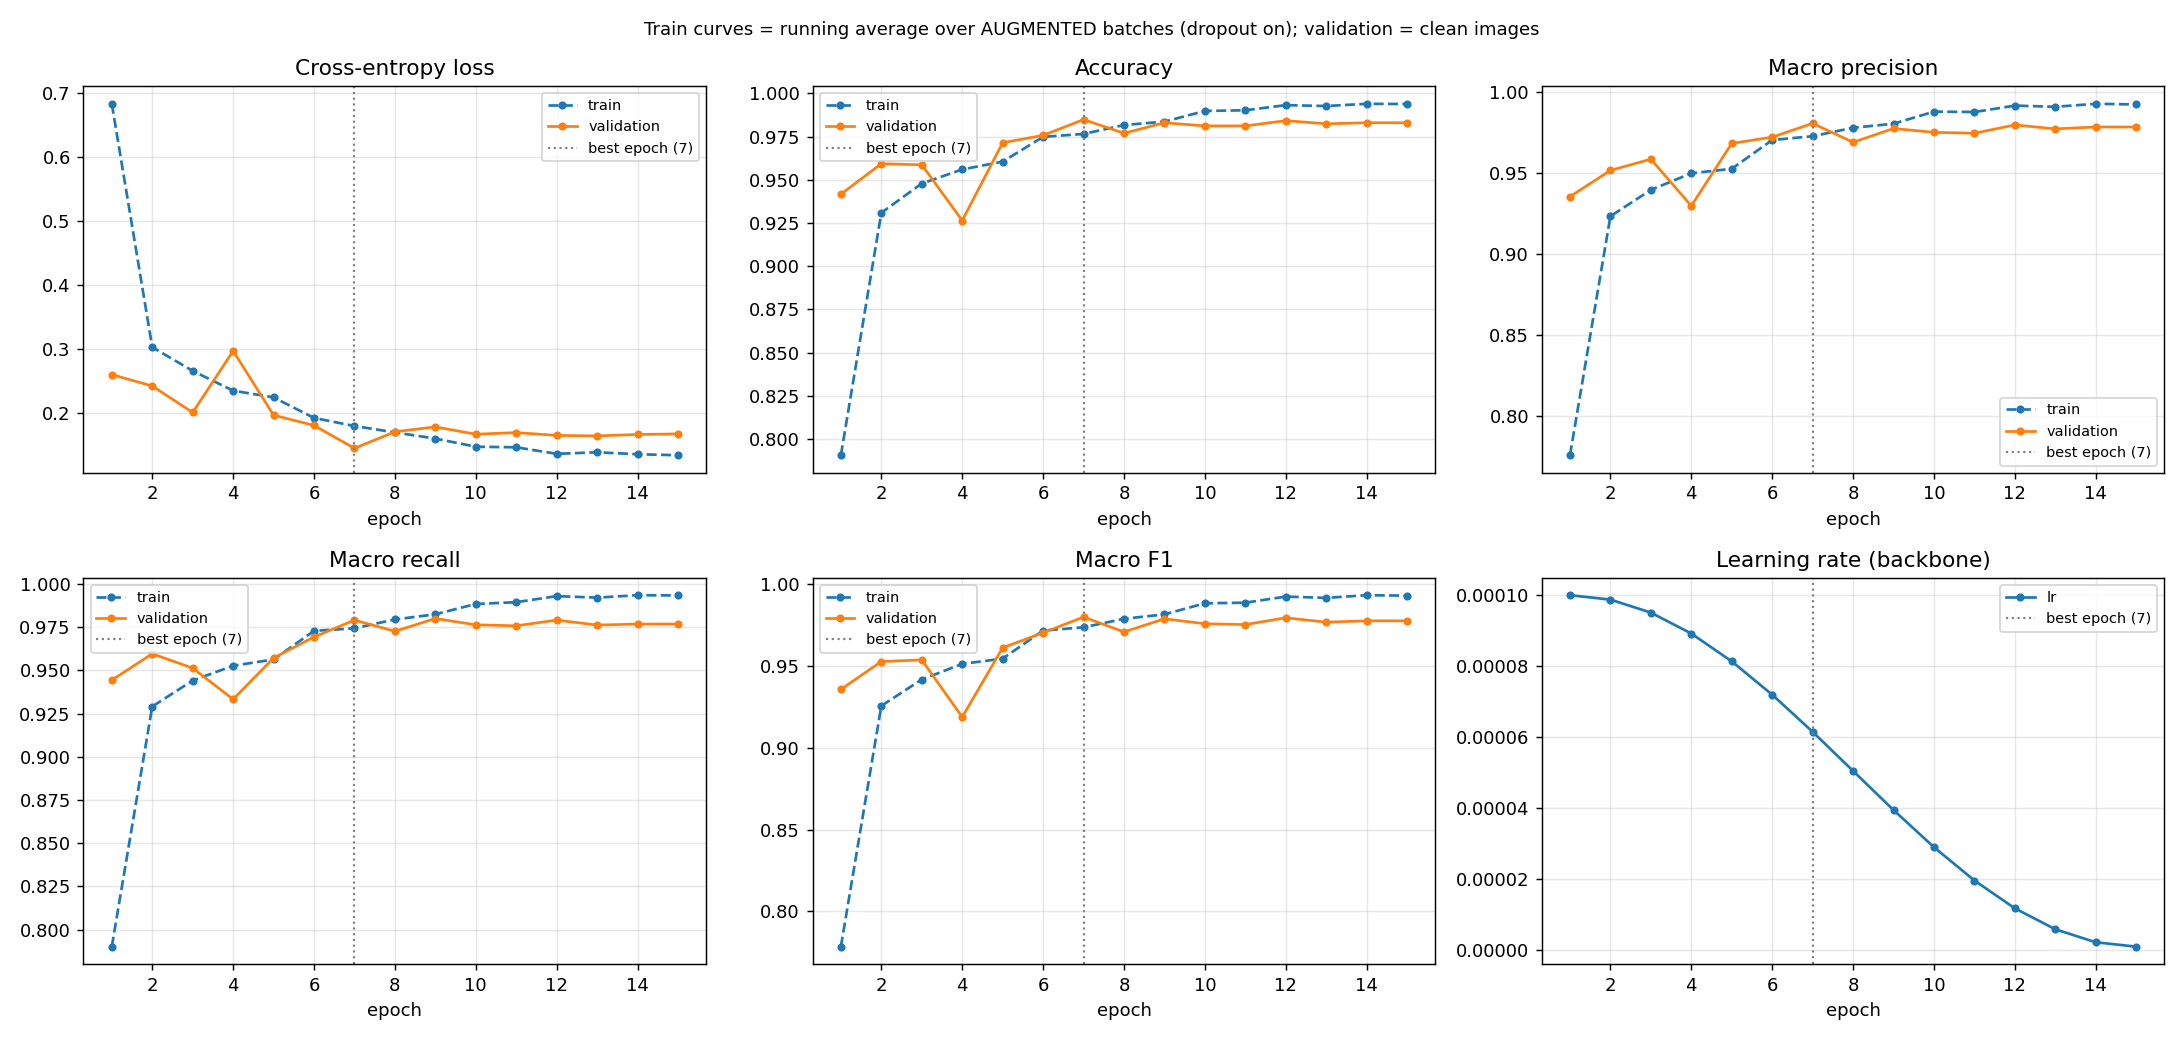


CONFUSION MATRIX - TEST (pooled PlantVillage + PlantDoc)


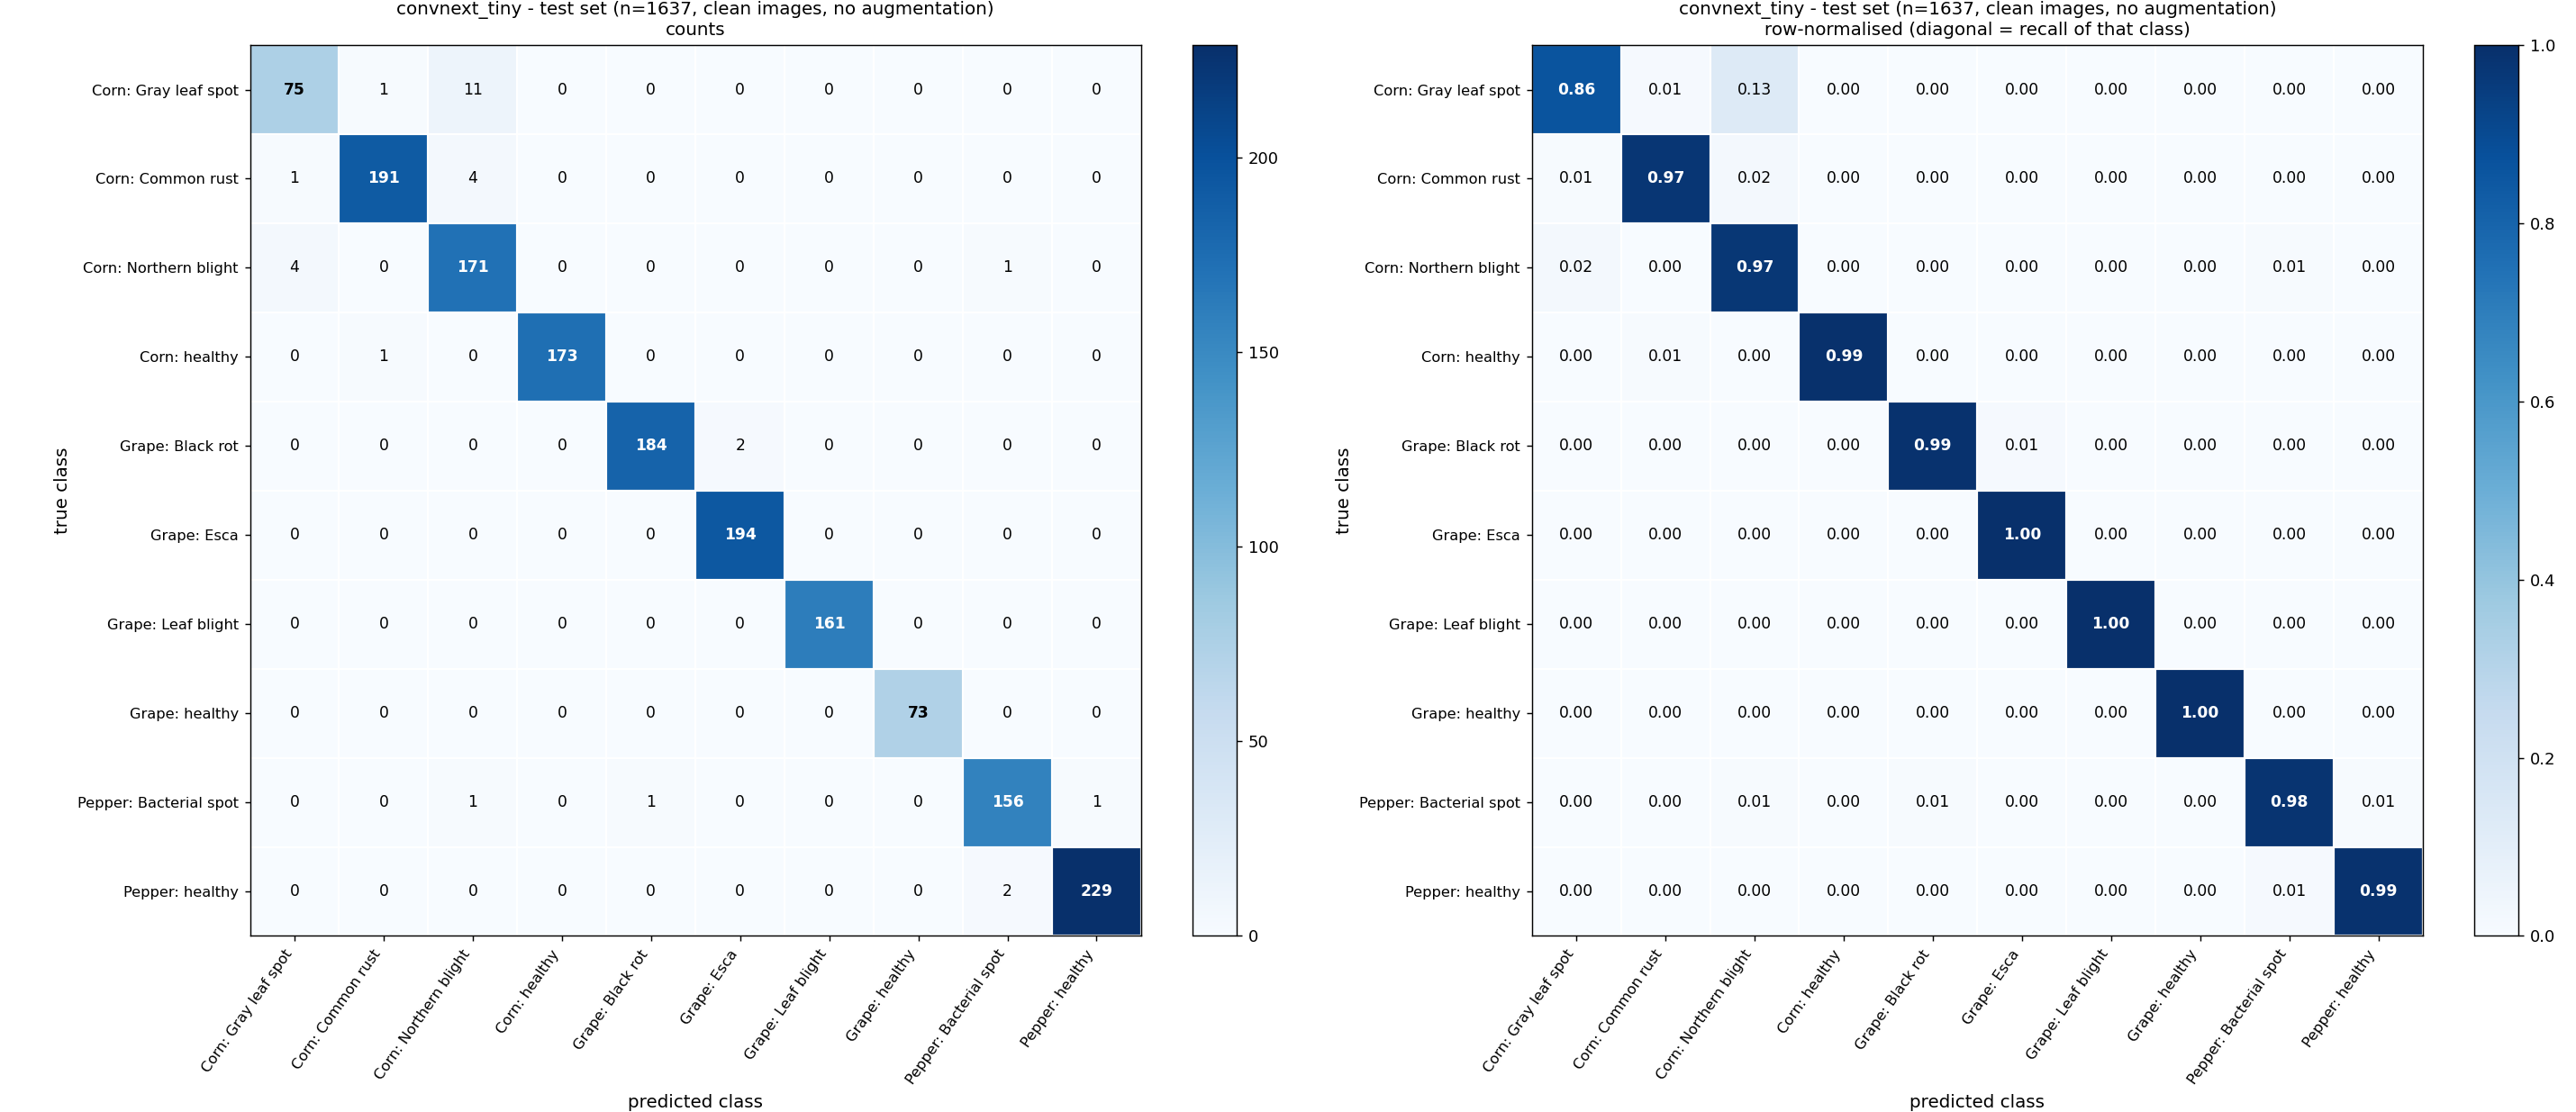


CONFUSION MATRIX - VALIDATION


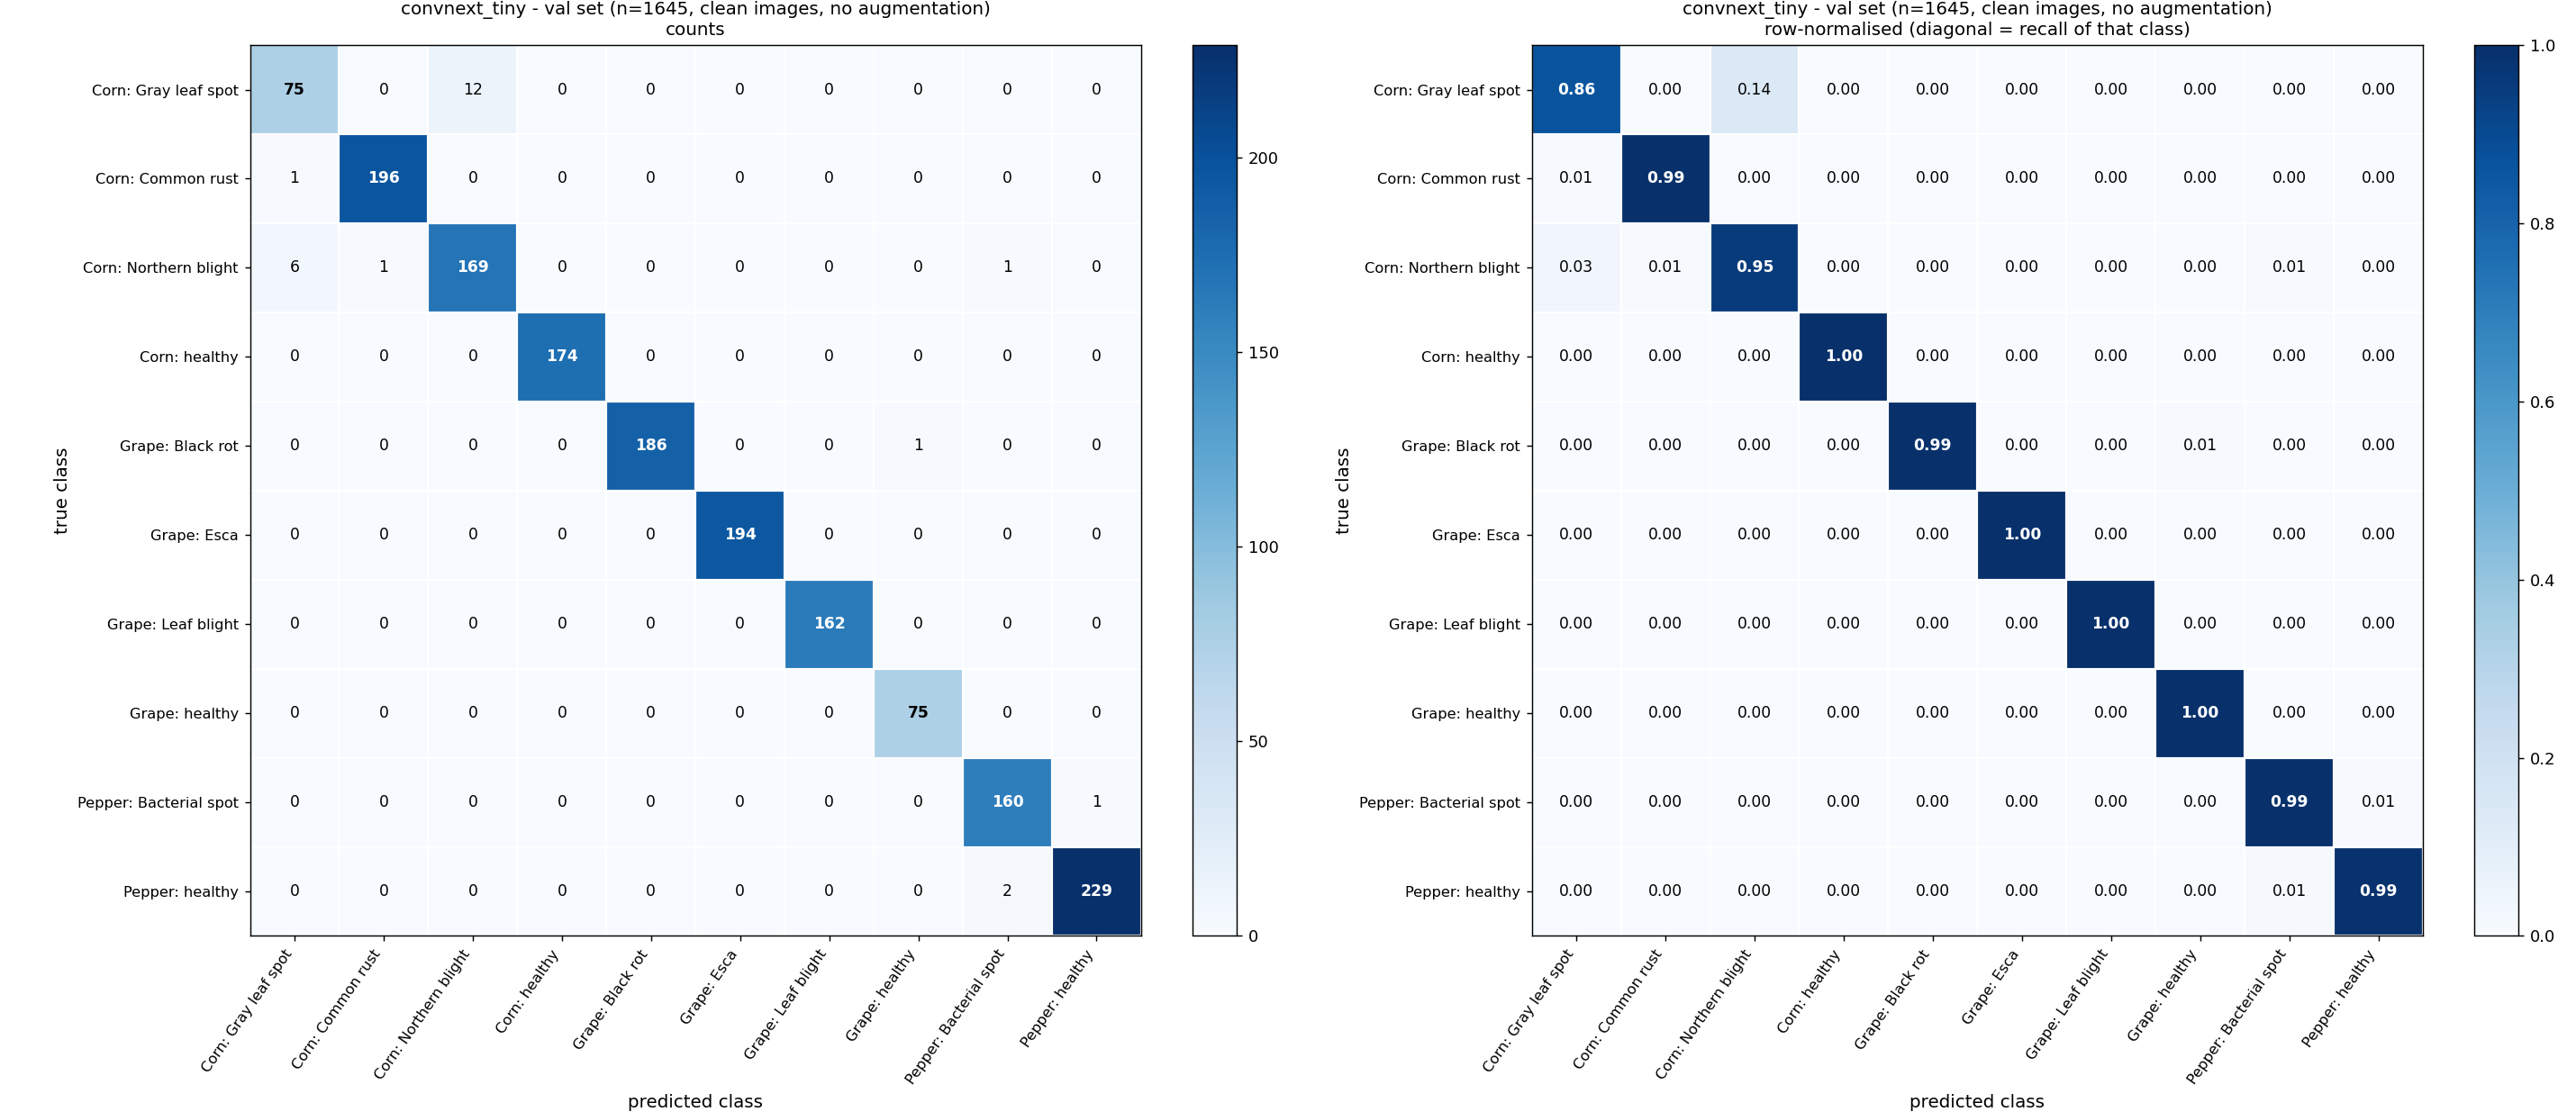


CONFUSION MATRIX - TRAIN


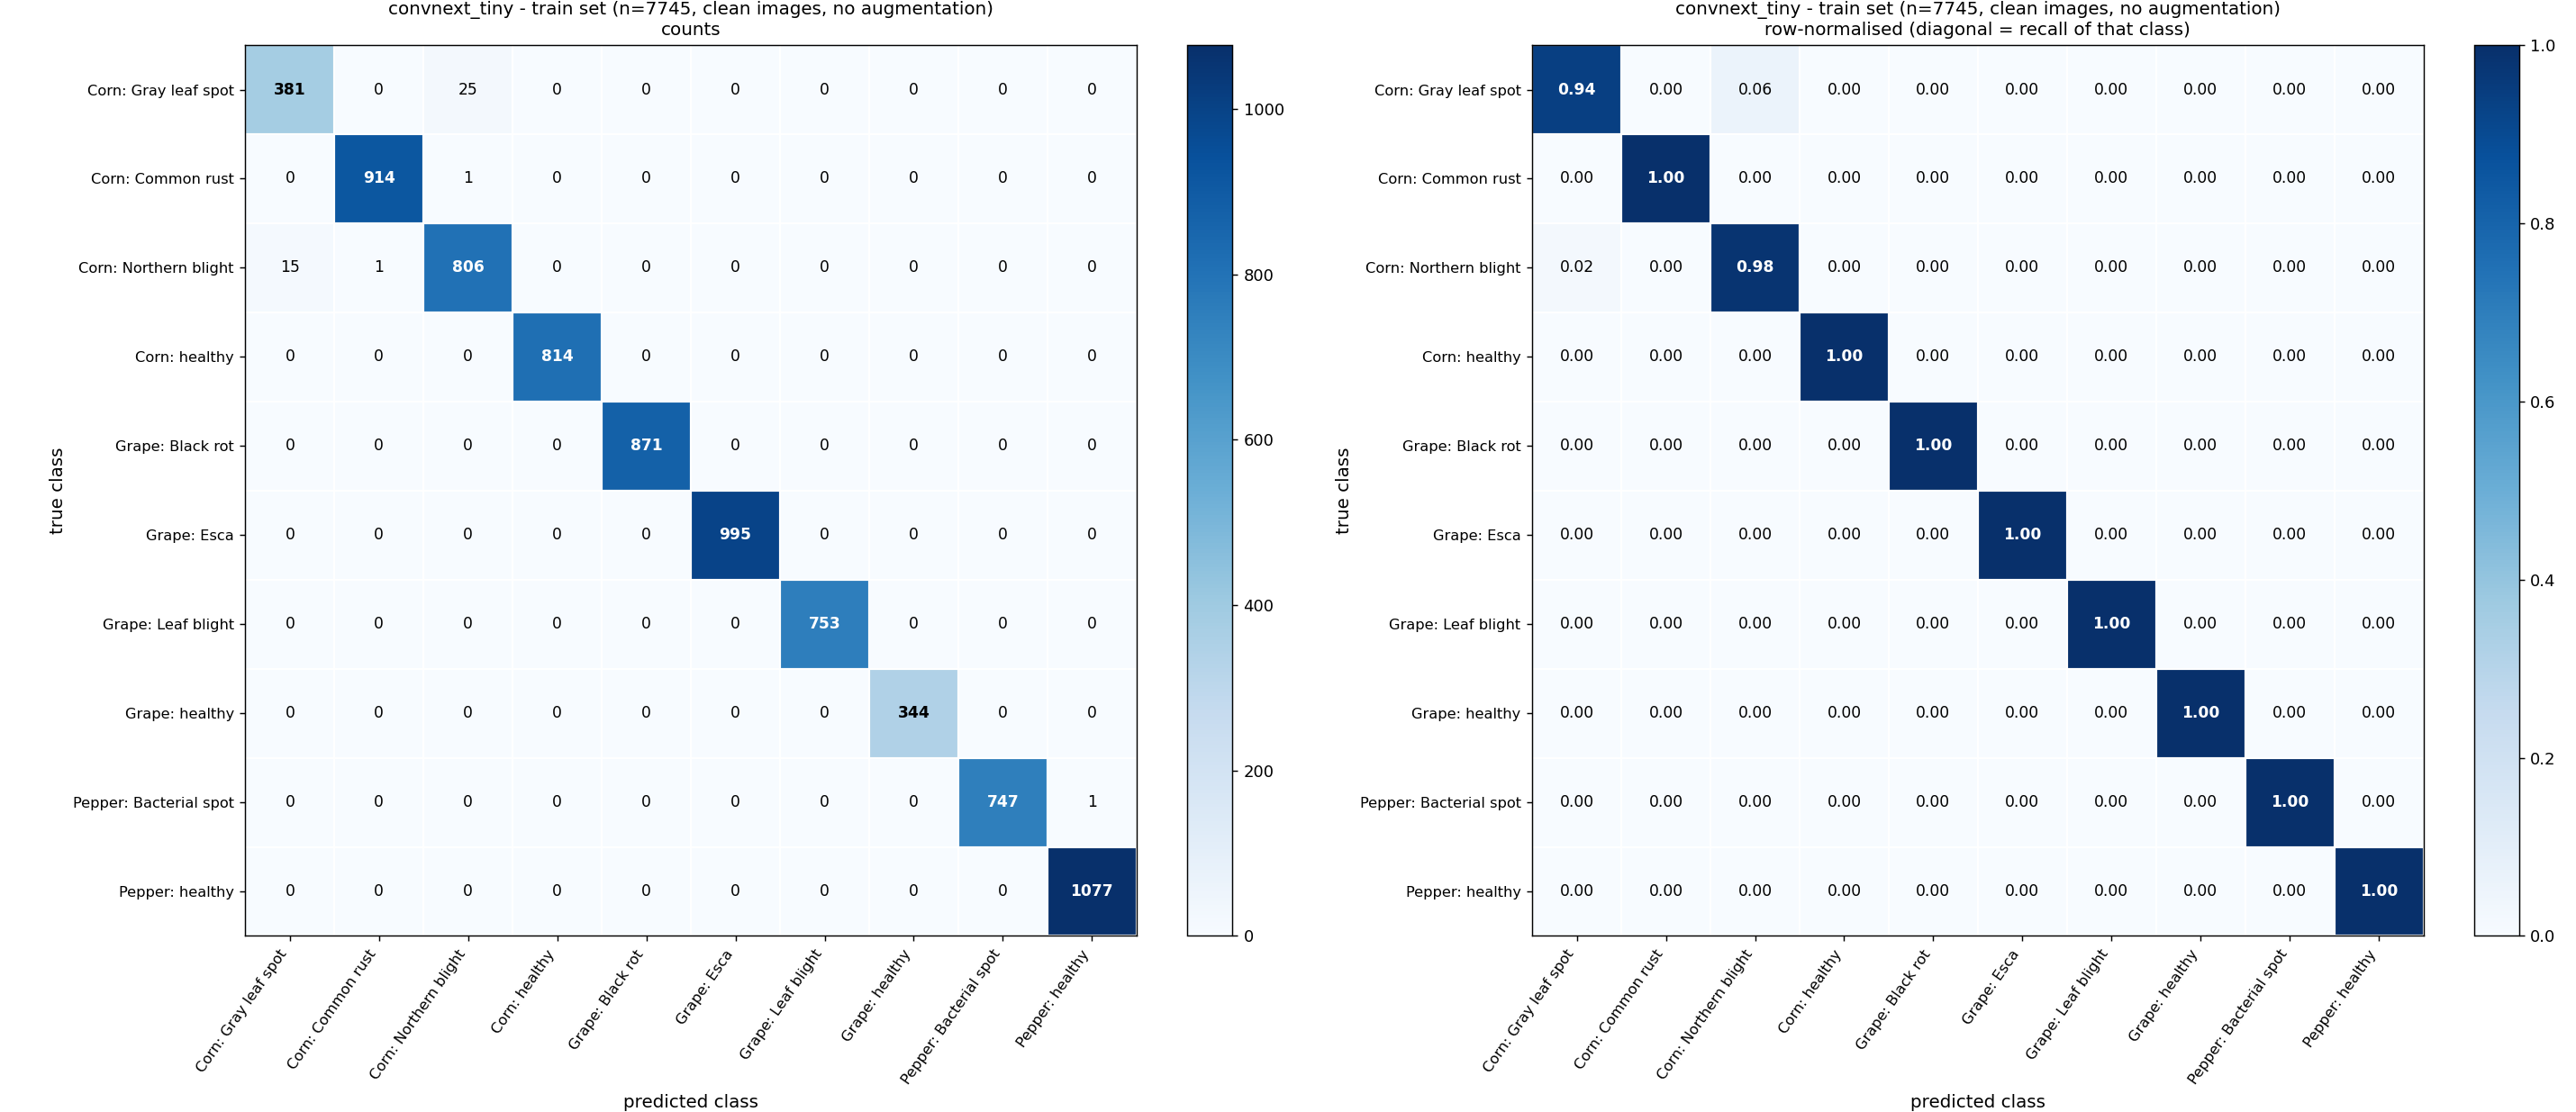


ROC curves - TEST


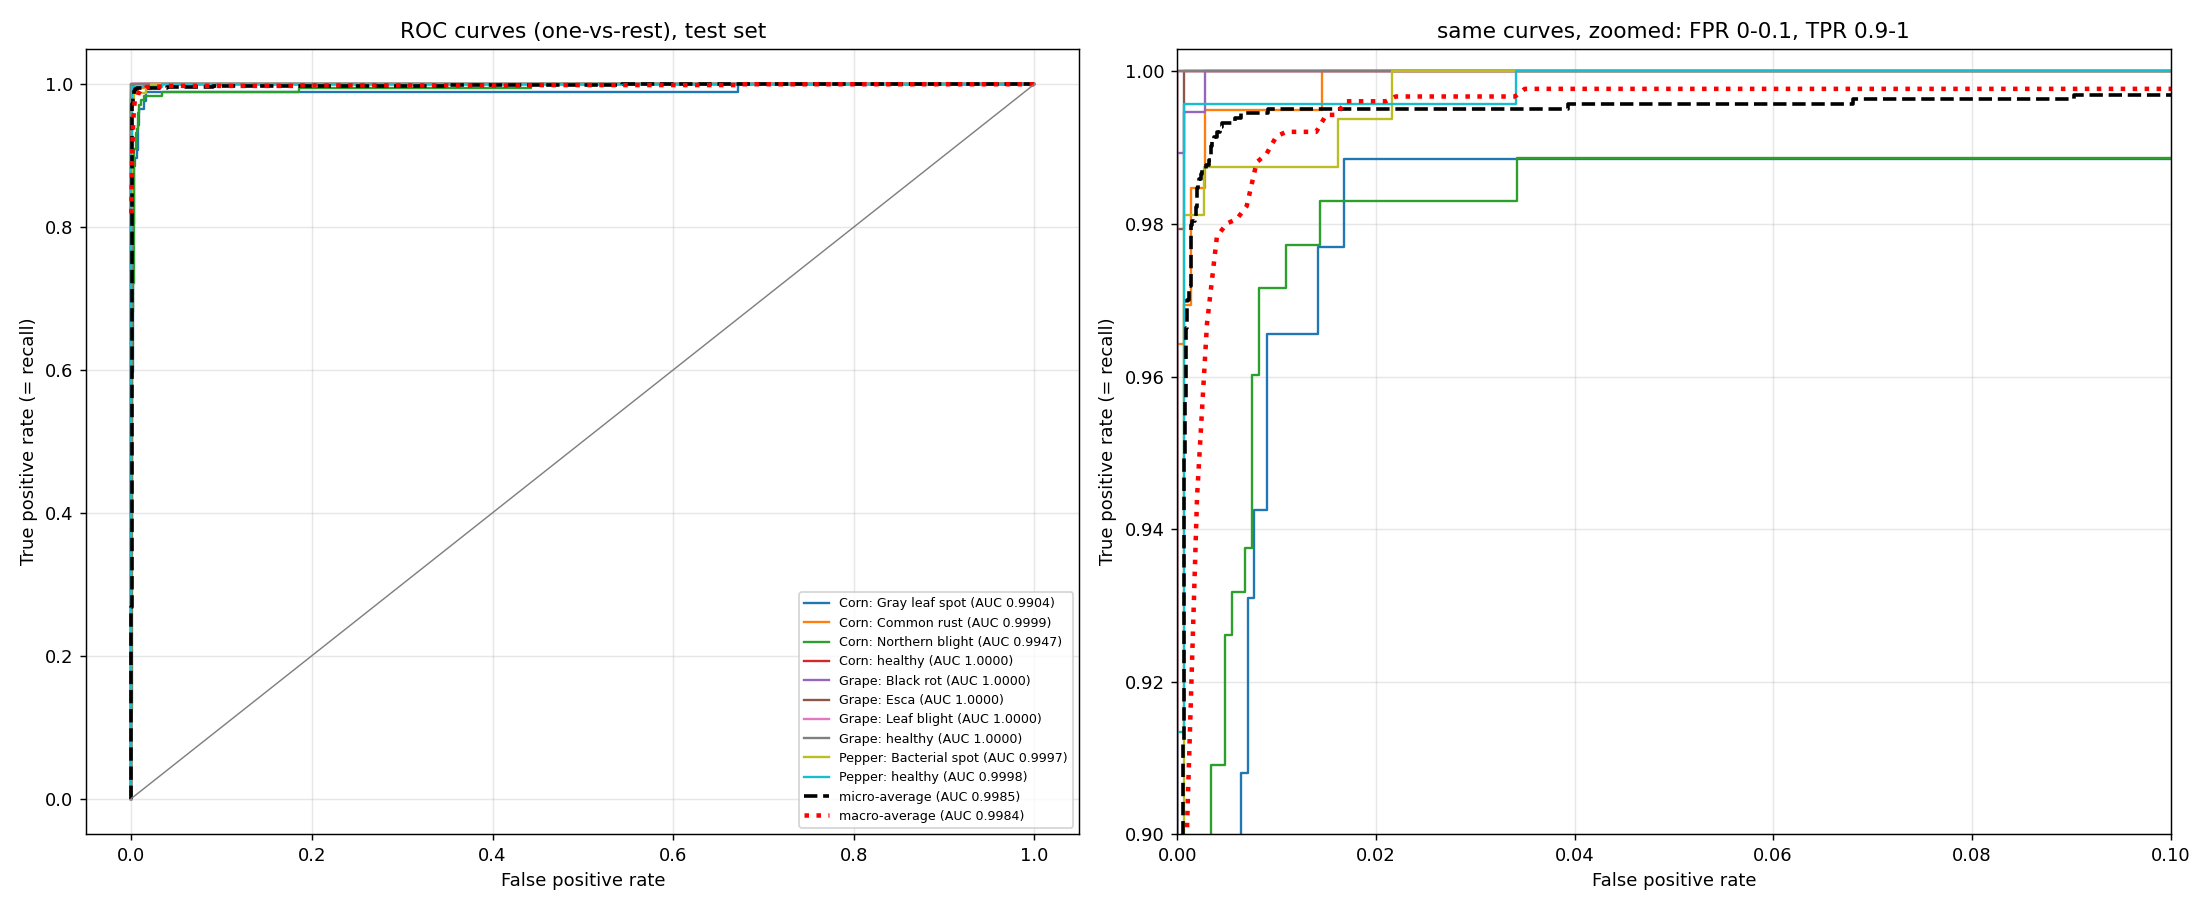


ROC curves - VALIDATION


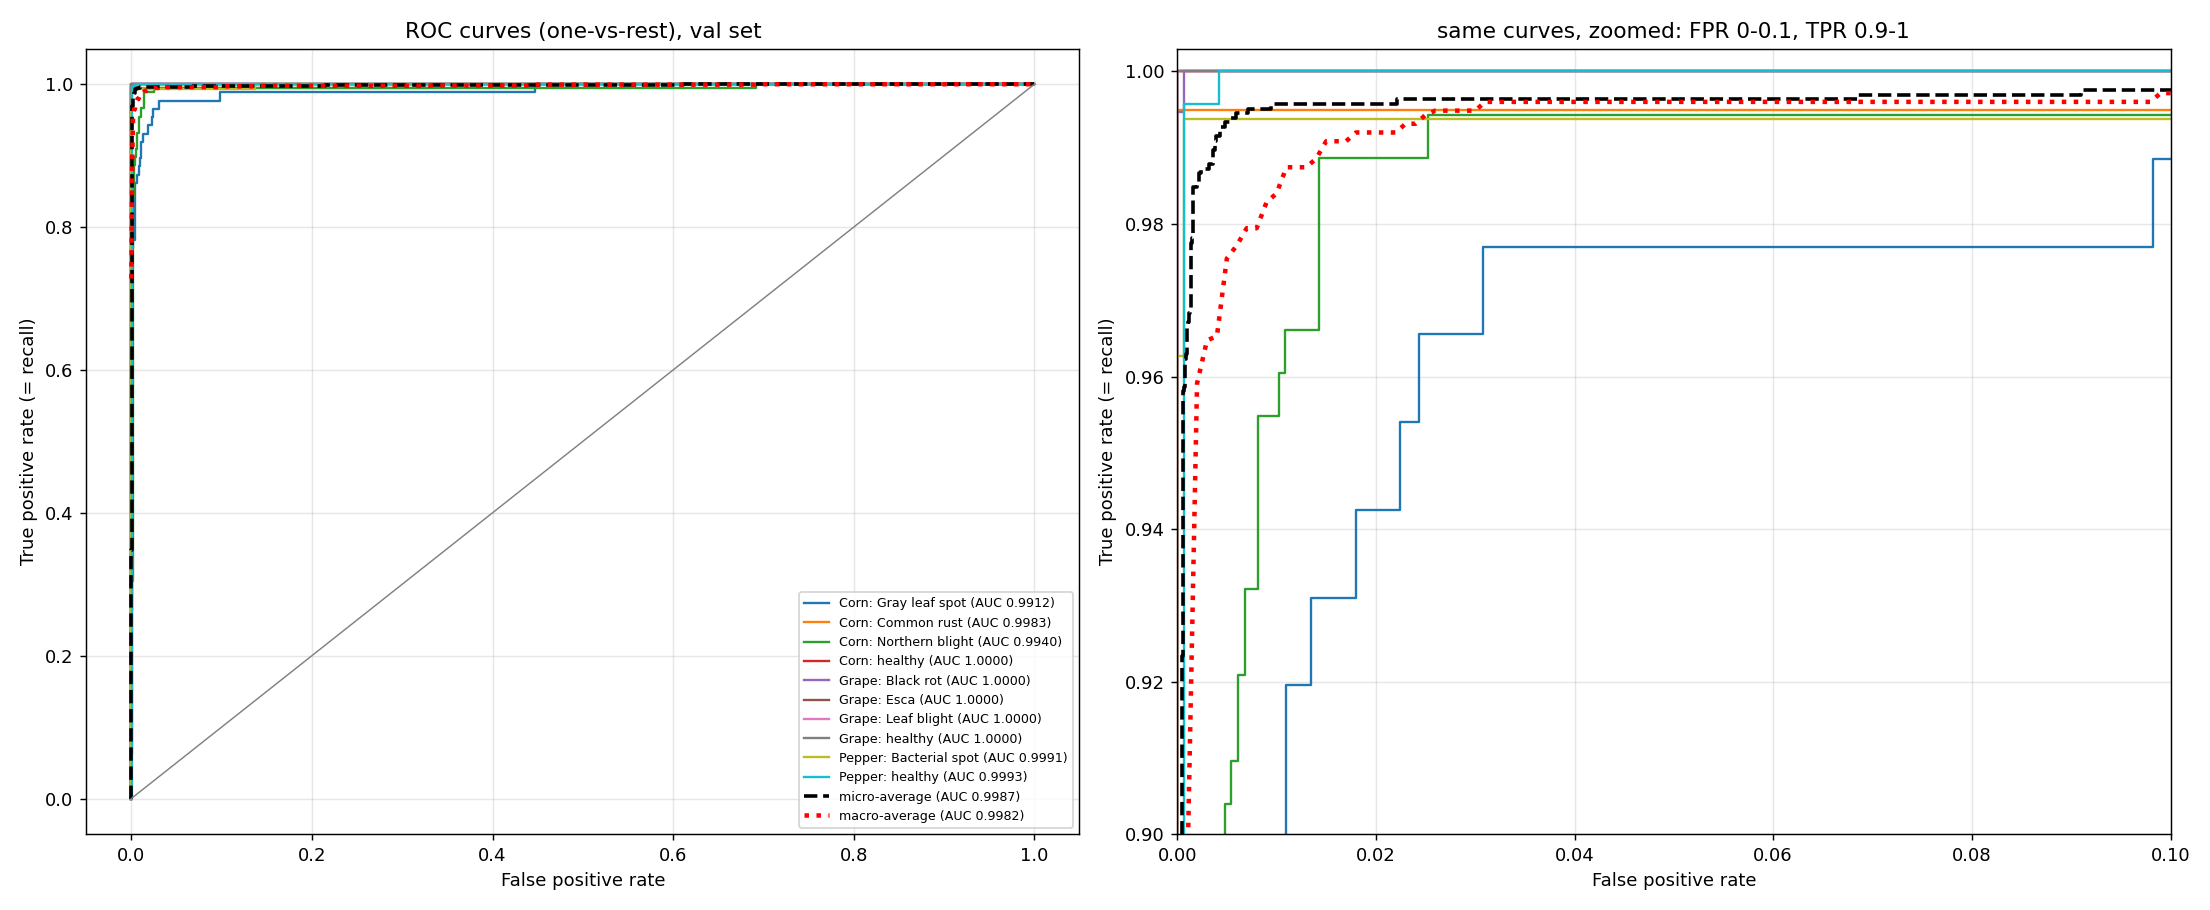


ROC curves - TRAIN


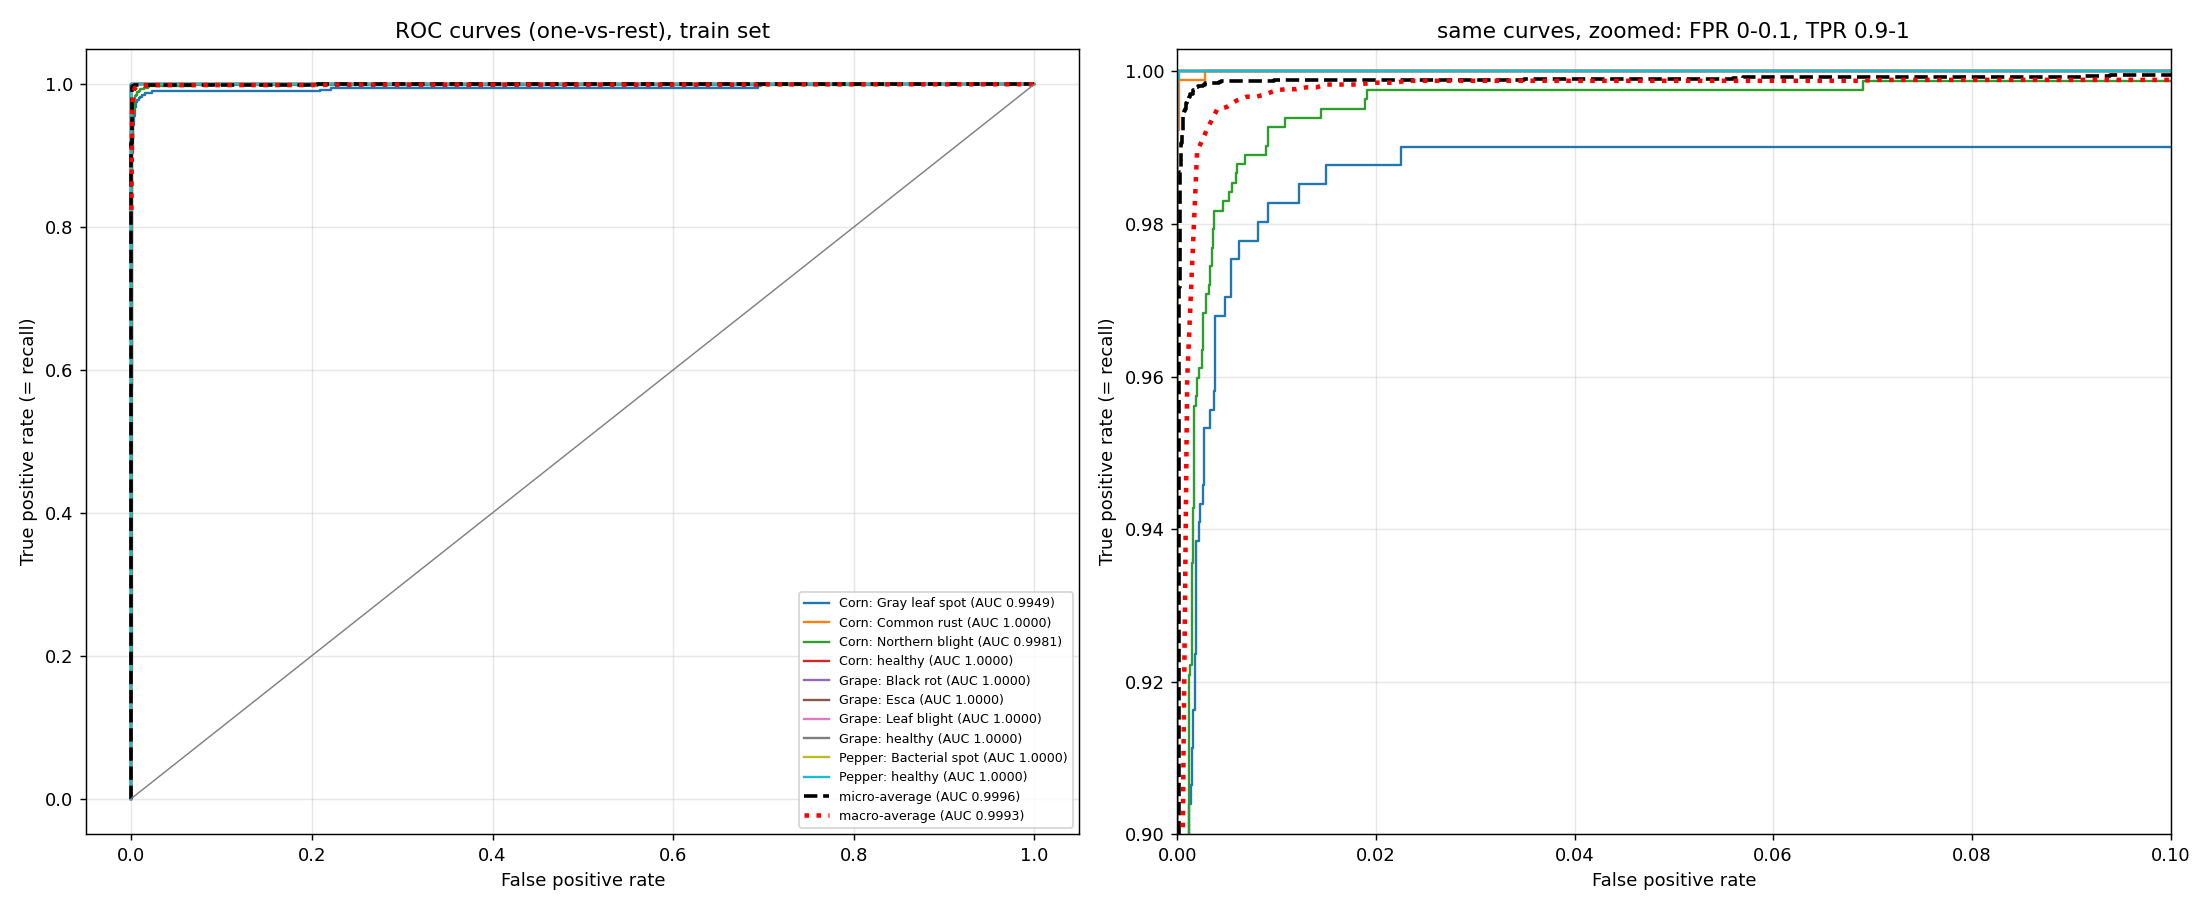


Per-class precision / recall / F1 - TEST


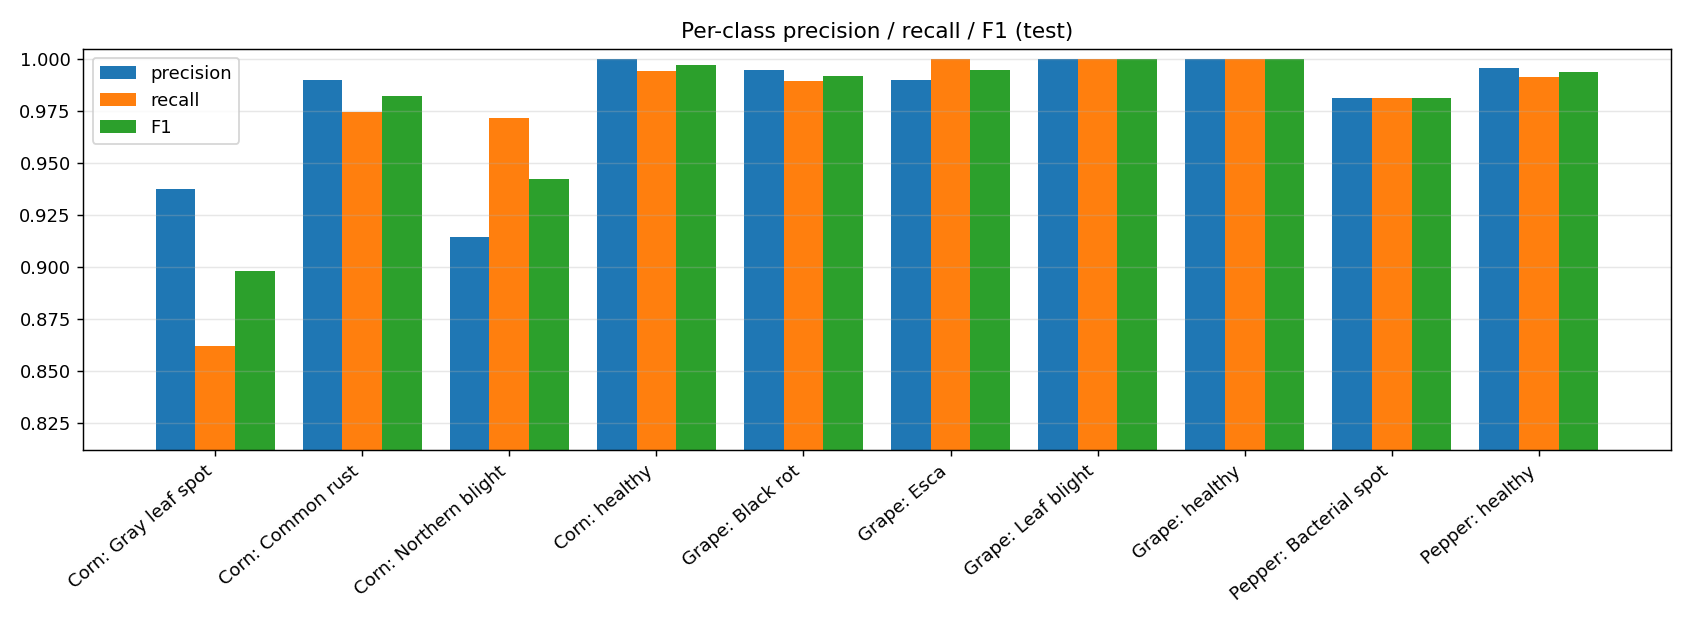


Calibration - TEST


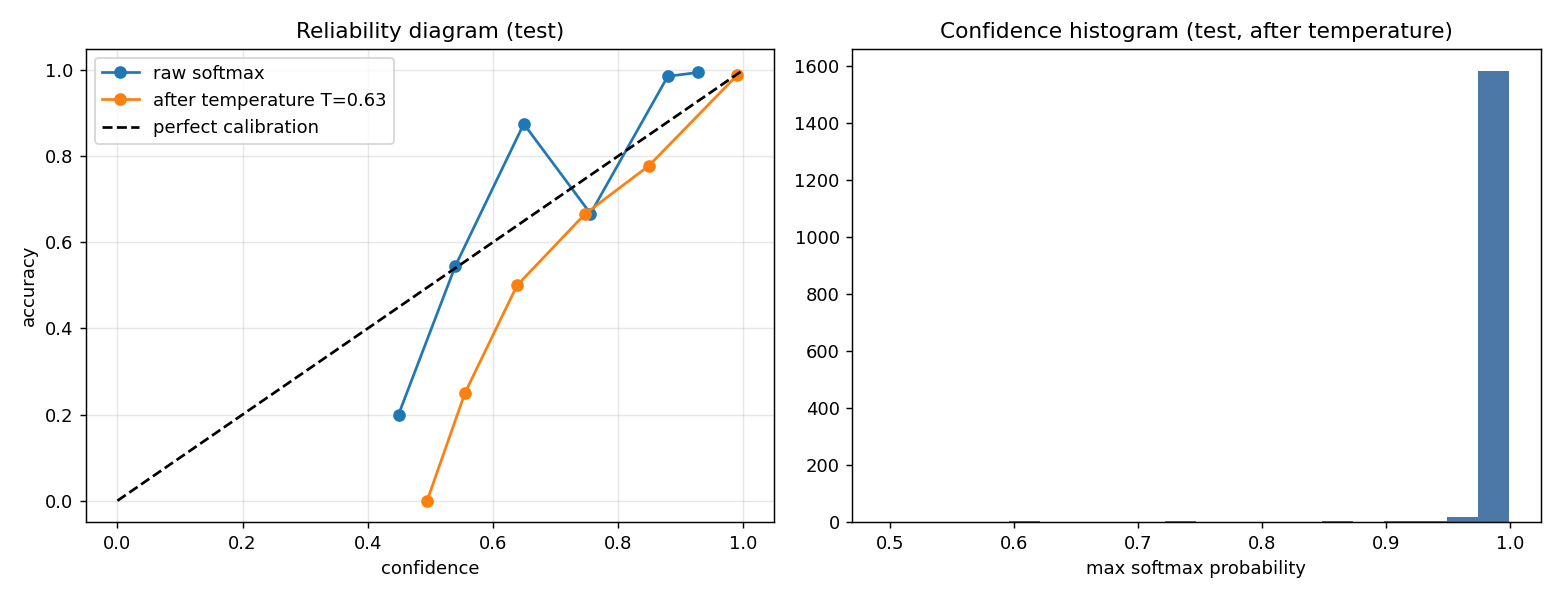


All files saved in /content/drive/MyDrive/plant-disease-v3/results/convnext_tiny/
['calibration_test.png', 'confusion_matrix_test.csv', 'confusion_matrix_test.png', 'confusion_matrix_train.csv', 'confusion_matrix_train.png', 'confusion_matrix_val.csv', 'confusion_matrix_val.png', 'full_report.txt', 'history.csv', 'metrics_summary.json', 'per_class_metrics.csv', 'per_class_metrics_test.png', 'roc_auc_per_class.csv', 'roc_test.png', 'roc_test_macro.npz', 'roc_train.png', 'roc_train_macro.npz', 'roc_val.png', 'roc_val_macro.npz', 'training_curves.png']


In [ ]:
import os, json, pandas as pd
from IPython.display import Image, display
OUT = f"/content/drive/MyDrive/plant-disease-v3/results/{MODEL}/"
s = json.load(open(OUT + "metrics_summary.json"))
print("Overall metrics (clean images, no augmentation):"); display(pd.DataFrame(s["splits"]).T.round(4))
for title, f in [("TRAIN vs VALIDATION per epoch: loss, accuracy, precision, recall, F1, learning rate", "training_curves.png"),
                 ("CONFUSION MATRIX - TEST (pooled PlantVillage + PlantDoc)", "confusion_matrix_test.png"),
                 ("CONFUSION MATRIX - VALIDATION", "confusion_matrix_val.png"), ("CONFUSION MATRIX - TRAIN", "confusion_matrix_train.png"),
                 ("ROC curves - TEST", "roc_test.png"), ("ROC curves - VALIDATION", "roc_val.png"), ("ROC curves - TRAIN", "roc_train.png"),
                 ("Per-class precision / recall / F1 - TEST", "per_class_metrics_test.png"), ("Calibration - TEST", "calibration_test.png")]:
    print("\n" + title); display(Image(OUT + f))
print("\nAll files saved in", OUT); print(sorted(os.listdir(OUT)))